# Module 2 Course Work - Applied Design and Prototype: Release Candidate
**Baseline Version:** ChallengeHub Prototype v0.2 (Lesson 7 / M2LA2 Reconciled Baseline)  

## Act 1 - Establish Baseline and Architecture-to-Code Mapping

### 1.1 Team Baseline & Operational Scope
* **Team Identifier & Implementation Baseline:** `Team01` ChallengeHub prototype v0.2 (Lesson 7 / M2LA2 verified implementation baseline passing 3/3 regression smoke tests).
* **Public Boundary Under Verification:** `ChallengeManager.record_activity(participant_id, challenge_id, activity_type, amount, activity_date, note="") -> ActivityRecord`.
* **Bounded Evidence Question:** Does the dynamic progress calculation query correctly aggregate valid activity amounts for enrolled participants in active challenges without triggering persistence side-effects or mutating accepted state upon invalid submissions?
* **Requirements & Contracts Traced:**
  * `FB-01` / `FB-02` & `UC-05`: Record valid activity and enforce discrete state append.
  * `FB-03` / `FB-04` & `NFB-02`: Precondition validations and strict failure invariant (zero accepted-state mutation on rejected input).
  * `FB-05` & `UC-04`: Dynamic metric progress derivation (amount-based and count-based) without mutable stored progress columns.
  * `FB-07` & `NFB-03`: Flat-file atomic write-through durability and reload reproducibility.

### 1.2 Authoritative Baseline Expectations & PO4 Reconciliation
* **Authoritative Dataset Scope:** Exactly 3 participants (`participants.json`), 2 challenges (`challenges.json`), 3 enrollments (`enrollments.json`), and 3 baseline activity records (`activities.csv`) with 0 schema violations.
* **Participant `P001` in Challenge `C001` (`Walk 20K`):** Exactly 2 valid baseline activity records (`AR-0001`: 3.5 km, `AR-0002`: 4.0 km) yielding an initial derived progress of **7.5 km**.
* **Canonical Goal Target & Reconciliation:** Canonical `challenges.json` defines `goal_target = 20.0 km` for `C001`, resulting in **37.5% baseline completion** (7.5 / 20.0). *(Note: Reconciles the provisional 10.0 km narrative reference from early PO4 drafting against the canonical data file without mutating the authoritative baseline).*
* **Participant `P003` in Challenge `C002` (`Focus Sessions`):** Exactly 1 valid baseline activity record (`AR-0003`: 1 session against a 5-session goal) yielding an initial derived progress of **1 session (20.0% completion)**.

### 1.3 Architecture-to-Code Mapping
The system preserves the 3-layer architecture established in Lesson 6 and M2LA1, enforcing strict unidirectional downward dependencies from Presentation to Domain and Persistence without circular coupling:

| Architectural Layer | Implementation Module / File | Primary Class or Functions | Responsibility Scope | Allowed Outbound Dependencies |
| :--- | :--- | :--- | :--- | :--- |
| **Presentation Layer** | `challengehub/cli.py` | `main()`, CLI argument handlers | Parses command-line inputs, coordinates user sessions, formats tabular and text console output. | Application Layer (`ChallengeManager`) |
| **Application Coordinator** | `challengehub/manager.py` | `ChallengeManager` | Central workflow coordinator. Orchestrates UC-05 precondition checks, invokes calculation strategies, and triggers atomic write-through. | Domain Entities, Strategies, Storage |
| **Domain Core & Logic** | `challengehub/models.py`<br>`challengehub/strategies.py` | `Participant`, `Challenge`, `Enrollment`, `ActivityRecord`<br>`ProgressStrategy`, `AmountProgressStrategy`, `CountProgressStrategy` | Encapsulates domain invariants, identity models, and metric calculation algorithms. | Independent Pure Python (No persistence or presentation imports) |
| **Data Persistence** | `challengehub/storage.py` | `load_participants()`, `load_challenges()`, `load_enrollments()`, `load_activities()`, `save_activities()` | Reads JSON/CSV files and serializes newly created `ActivityRecord` instances to flat storage. | Standard Library (`csv`, `json`, `pathlib`) |

In [169]:
import os
import sys
import json
import shutil
import tempfile
import subprocess
from pathlib import Path
from datetime import date
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    IN_COLAB = True
    drive.mount("/content/drive")
except ImportError:
    IN_COLAB = False

candidates = []
configured = os.environ.get("CHALLENGEHUB_ROOT")
if configured:
    candidates.append(Path(configured).expanduser().resolve())
if IN_COLAB:
    candidates.extend([Path("/content/drive/MyDrive/ChallengeHub"), Path("/content/ChallengeHub")])
current = Path.cwd().resolve()
candidates.extend([current, current / "ChallengeHub", *current.parents])

PROJECT_ROOT = next((p for p in candidates if (p / "challengehub").is_dir() and (p / "data").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("ChallengeHub project root not found. Ensure repository is placed at My Drive/ChallengeHub.")

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("ChallengeHub Connected at:", PROJECT_ROOT)
print("Data Directory:", DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ChallengeHub Connected at: /content/drive/MyDrive/ChallengeHub
Data Directory: /content/drive/MyDrive/ChallengeHub/data


In [170]:
#Baseline Regression Test Suite
baseline_pytest = subprocess.run([sys.executable, "-m", "pytest", "-q"], cwd=PROJECT_ROOT, text=True, capture_output=True)
print(baseline_pytest.stdout)
if baseline_pytest.stderr.strip():
    print(baseline_pytest.stderr)
assert baseline_pytest.returncode == 0, "Baseline test suite failed!"


...                                                                      [100%]
3 passed in 0.06s



## Act 2 - Architecture and Pattern Decision Audit

### Pattern Decision Evaluation Matrix
To ensure architectural patterns directly resolve concrete operational pressures rather than serving as decorative bloat:

| Pattern Candidate | Operational Pressure / Technical Need | Final Team Decision | Trade-Off & Justification |
| :--- | :--- | :--- | :--- |
| **Strategy Pattern** | Challenges define fundamentally different progress accumulation models (e.g., distance `amount` vs session `count`). | **Selected & Implemented** | Extracted `AmountProgressStrategy` and `CountProgressStrategy` implementing `ProgressStrategy`. Decouples metric calculations from `ChallengeManager.progress()`, adhering to the Open/Closed Principle. |
| **Repository Pattern** | Direct file I/O in `storage.py` couples `ChallengeManager` to flat-file CSV/JSON representations. | **Simplified / Deferred** | Retained direct write-through routines in `storage.py` for Module 2. Abstracting a generic persistence repository was deferred to Module IS when SQLite relational persistence is introduced. |
| **Observer Pattern** | Need to issue notifications or trigger milestone achievements upon logging an activity. | **Rejected** | The current prototype is a synchronous, single-threaded CLI application. Event broadcasters and listeners add unneeded execution overhead and debugging complexity. |
| **Factory Pattern** | Creation of distinct `ActivityRecord` variants across diverse challenge categories. | **Rejected** | Schema inspection confirms all activities share identical schema attributes (`record_id`, `participant_id`, `challenge_id`, `activity_type`, `amount`, `activity_date`, `note`). Direct instantiation via dataclass is concise and maintainable. |

In [171]:
def configure_application(project_root):
    if str(project_root) not in sys.path:
        sys.path.insert(0, str(project_root))
    for name in list(sys.modules):
        if name == "challengehub" or name.startswith("challengehub."):
            del sys.modules[name]
    try:
        from challengehub import build_application, save_application_data
        def build(data_dir): return build_application(data_dir)
        def count(app): return len(app["activities"].all())
        def record(app, pid, cid, atype, amount, when, note=""): return app["activity_service"].record(pid, cid, atype, amount, when, note)
        def progress(app, pid, cid): return app["progress_service"].get(pid, cid).total
        def save(app, target): return save_application_data(app, target)
        return build, count, record, progress, save, "service/reference API"
    except ImportError:
        from challengehub.manager import ChallengeManager
        def build(data_dir): return ChallengeManager(data_dir)
        def count(app): return len(app.activities)
        def record(app, pid, cid, atype, amount, when, note=""): return app.record_activity(pid, cid, atype, amount, when, note)
        def progress(app, pid, cid): return app.progress(pid, cid)["total"]
        return build, count, record, progress, None, "legacy manager API"

build_app, activity_count, record_activity, progress_total, save_app, API_KIND = configure_application(PROJECT_ROOT)
print("Application Adapter Configured:", API_KIND)
assert API_KIND == "legacy manager API"

Application Adapter Configured: legacy manager API


## Act 3 - Integrated PO4 Data Evidence and Visualizations

Authoritative baseline verification traces directly to `activities.csv`, `participants.json`, `challenges.json`, and `enrollments.json`. The baseline must satisfy all schema and referential constraints with zero silent modifications, while isolating any synthetic probe defects.

In [172]:
#Load Data
activities_raw = pd.read_csv(DATA_DIR / "activities.csv")
participants = pd.DataFrame(json.loads((DATA_DIR / "participants.json").read_text(encoding="utf-8")))
challenges = pd.DataFrame(json.loads((DATA_DIR / "challenges.json").read_text(encoding="utf-8")))
enrollments = pd.DataFrame(json.loads((DATA_DIR / "enrollments.json").read_text(encoding="utf-8")))

activities = activities_raw.copy()
activities["amount"] = pd.to_numeric(activities["amount"], errors="coerce")
activities["activity_date"] = pd.to_datetime(activities["activity_date"], errors="coerce").dt.date

participant_ids = set(participants["participant_id"].astype(str))
challenge_map = challenges.set_index("challenge_id").to_dict("index")
enrolled_pairs = set(zip(enrollments["participant_id"].astype(str), enrollments["challenge_id"].astype(str)))

In [173]:
#Validation Function
def validate_row(row):
    reasons = []
    if pd.isna(row["amount"]) or row["amount"] <= 0:
        reasons.append("invalid amount")
    if str(row["participant_id"]) not in participant_ids:
        reasons.append("unknown participant")
    if str(row["challenge_id"]) not in challenge_map:
        reasons.append("unknown challenge")
    elif (str(row["participant_id"]), str(row["challenge_id"])) not in enrolled_pairs:
        reasons.append("not enrolled")
    else:
        c = challenge_map[str(row["challenge_id"])]
        if str(row["activity_type"]).strip().lower() != str(c["activity_type"]).strip().lower():
            reasons.append("type mismatch")
        c_start = pd.to_datetime(c["start_date"]).date()
        c_end = pd.to_datetime(c["end_date"]).date()
        if not (c_start <= row["activity_date"] <= c_end):
            reasons.append("date out of range")
    return "; ".join(reasons)

In [174]:
#Audit Baseline
baseline_issues = []
for idx, row in activities.iterrows():
    err = validate_row(row)
    if err:
        baseline_issues.append({"row": idx, "record_id": row["record_id"], "reasons": err})

print("Baseline Activity Rows:", len(activities))
print(f"Authoritative Validation Findings: {len(baseline_issues)} (Expected: 0)")
assert len(baseline_issues) == 0, "Authoritative baseline has unexpected defects!"

Baseline Activity Rows: 3
Authoritative Validation Findings: 0 (Expected: 0)


In [175]:
#Synthetic Probe Isolation Check
synthetic_probe = pd.Series({
    "record_id": "AR-MALFORMED-DEMO",
    "participant_id": "P999",
    "challenge_id": "C001",
    "activity_type": "walk",
    "amount": -1.0,
    "activity_date": date(2026, 8, 3),
    "note": "Synthetic probe"
})
probe_finding = validate_row(synthetic_probe)
print("Synthetic Probe Defect Detection:", probe_finding)
assert "unknown participant" in probe_finding and "invalid amount" in probe_finding
print("Authoritative baseline remains unmodified at exactly 3 rows.")

Synthetic Probe Defect Detection: invalid amount; unknown participant; not enrolled
Authoritative baseline remains unmodified at exactly 3 rows.


In [176]:
PID = "P001"
CID = "C001"

selected = activities[(activities["participant_id"] == PID) & (activities["challenge_id"] == CID)].sort_values("activity_date").copy()
selected["cumulative_amount"] = selected["amount"].cumsum()

summary_df = pd.DataFrame([{
    "participant_id": PID,
    "challenge_id": CID,
    "activity_count": int(len(selected)),
    "total_amount": float(selected["amount"].sum())
}])

display(selected)

,record_id,participant_id,challenge_id,activity_type,amount,activity_date,note,cumulative_amount
0,AR-0001,P001,C001,walk,3.5,2026-08-03,Morning walk,3.5
1,AR-0002,P001,C001,walk,4.0,2026-08-05,Campus walk,7.5


In [177]:
display(summary_df)

assert summary_df.loc[0, "activity_count"] == 2
assert summary_df.loc[0, "total_amount"] == 7.5

,participant_id,challenge_id,activity_count,total_amount
0,P001,C001,2,7.5


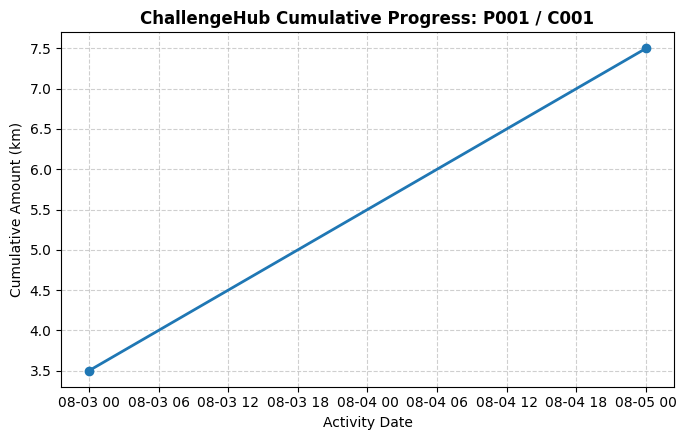

Visualization saved to: /content/drive/MyDrive/ChallengeHub/outputs/po4_cumulative_progress.png


In [178]:
#Progress Chart
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(selected["activity_date"], selected["cumulative_amount"], marker="o", color="#1f77b4", linewidth=2, label="Cumulative Distance")
ax.set_title(f"ChallengeHub Cumulative Progress: {PID} / {CID}", fontsize=12, fontweight="bold")
ax.set_xlabel("Activity Date", fontsize=10)
ax.set_ylabel("Cumulative Amount (km)", fontsize=10)
ax.grid(True, linestyle="--", alpha=0.6)
fig.tight_layout()

chart_path = OUTPUT_DIR / "po4_cumulative_progress.png"
fig.savefig(chart_path, dpi=160)
plt.show()
print("Visualization saved to:", chart_path)

### Interpretation & PO4 Evidence Claim
* **Claim:** For participant `P001` in distance-based challenge `C001`, the system dynamically derives an active accumulated progress of 7.5 km across 2 validated activity entries, demonstrating that progress is an in-memory aggregation of accepted domain events rather than a statically stored, mutable counter.
* **Evidence (rows/summary/transformation):** Authoritative records `AR-0001` (3.5 km on 2026-08-03) and `AR-0002` (4.0 km on 2026-08-05) from `activities.csv` passed all 6 validation layers with zero exclusions. Chronological cumulative transformation yields 3.5 km -> 7.5 km, which directly matches the pandas summary output (`activity_count = 2`, `total_amount = 7.5`) and the visual progression in `po4_cumulative_progress.png`.
* **Application rule or requirement connected to the claim:** Functional Requirements FB-03 (precondition validation before storage), FB-05 (amount-based dynamic progress calculation model), and Use Cases UC-04 (View Challenge Progress) / UC-05 (Record Activity), which dictate that progress must reflect the derived sum of valid enrolled records.
* **Limitation & Reconciliation:** The current dataset slice contains only two discrete date points for this participant/challenge pair, rendering the trend as a single linear segment; furthermore, the summary and chart examine only distance accumulation without displaying the canonical target goal benchmark (20.0 km) or modeling intra-day time intervals.

## Act 4 - Prototype Verification Matrix and Fresh-Extraction Reproducibility

To ensure Release Candidate integrity, this act executes two rigorous verification layers:
1. Operational contract verification covering normal execution, date boundaries, and invalid failure invariants.
2. An automated clean-room extraction test running pytest and runtime probes directly from `Team01_M2CW_Codebase.zip`.

In [179]:
tmp_dir = tempfile.TemporaryDirectory()
VERIFY_DATA = Path(tmp_dir.name) / "data"
shutil.copytree(DATA_DIR, VERIFY_DATA)

test_app = build_app(VERIFY_DATA)
initial_count = activity_count(test_app)
initial_progress = progress_total(test_app, "P001", "C001")

print(f"Isolated Environment Started | Count: {initial_count} | Total: {initial_progress}")
assert initial_count == 3 and initial_progress == 7.5

Isolated Environment Started | Count: 3 | Total: 7.5


In [180]:
#Normal Path Execution
rec_norm = record_activity(test_app, "P001", "C001", "walk", 2.0, date(2026, 8, 10), "Normal execution")
count_after_norm = activity_count(test_app)
progress_after_norm = progress_total(test_app, "P001", "C001")
print(f"Normal Case Passed: Count -> {count_after_norm}, Progress -> {progress_after_norm}")
assert count_after_norm == 4 and progress_after_norm == 9.5

Activity recorded for P001: 2 km
Normal Case Passed: Count -> 4, Progress -> 9.5


In [181]:
#Boundary Valid Execution (Start date boundary, small positive amount)
rec_bound = record_activity(test_app, "P001", "C001", "walk", 0.01, date(2026, 8, 1), "Boundary check")
count_after_bound = activity_count(test_app)
print(f"Boundary Case Passed: Count -> {count_after_bound}")
assert count_after_bound == 5


Activity recorded for P001: 0.01 km
Boundary Case Passed: Count -> 5


In [182]:
#Failure Invariant Check (Amount = 0 must fail with ZERO mutation)
count_before_fail = activity_count(test_app)
progress_before_fail = progress_total(test_app, "P001", "C001")
try:
    record_activity(test_app, "P001", "C001", "walk", 0, date(2026, 8, 10), "Invalid submission")
    raise AssertionError("Validation failed to reject zero amount!")
except ValueError as e:
    print(f"Invalid Request Correctly Rejected: {type(e).__name__} - {e}")

count_after_fail = activity_count(test_app)
progress_after_fail = progress_total(test_app, "P001", "C001")
assert count_after_fail == count_before_fail == 5, "Failure invariant violated: count mutated!"
assert progress_after_fail == progress_before_fail, "Failure invariant violated: progress mutated!"

Invalid Request Correctly Rejected: ValueError - Amount must be positive


In [183]:
#Persistence Reload Coherence Check
persisted_lines = (VERIFY_DATA / "activities.csv").read_text(encoding="utf-8").strip().splitlines()
assert len(persisted_lines) == 6, f"Expected 6 lines on disk (1 header + 5 rows), got {len(persisted_lines)}"

reloaded_app = build_app(VERIFY_DATA)
assert activity_count(reloaded_app) == 5
assert round(progress_total(reloaded_app, "P001", "C001"), 2) == 9.51
print("Persistence Durability & Reload Coherence: 100% Verified.")

Persistence Durability & Reload Coherence: 100% Verified.


In [184]:
import zipfile

codebase_zip = OUTPUT_DIR / "Team01_M2CW_Codebase.zip"
assert codebase_zip.exists(), f"Missing codebase bundle at {codebase_zip}"

clean_extract_dir = Path(tempfile.mkdtemp(prefix="m2cw_clean_"))
with zipfile.ZipFile(codebase_zip, "r") as archive:
    archive.extractall(clean_extract_dir)

print("Extracted Clean Room Codebase to:", clean_extract_dir)
fresh_pytest = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", "--color=no"],
    cwd=clean_extract_dir,
    text=True,
    capture_output=True
)
print("Fresh Extract Pytest Result:\n", fresh_pytest.stdout)
if fresh_pytest.stderr.strip():
    print(fresh_pytest.stderr)
assert fresh_pytest.returncode == 0, "Clean room fresh-extraction failed pytest suite!"

sys.path.insert(0, str(clean_extract_dir))
from challengehub.manager import ChallengeManager

fresh_manager = ChallengeManager(clean_extract_dir / "data")
assert len(fresh_manager.activities) == 3
assert fresh_manager.progress("P001", "C001")["total"] == 7.5

Extracted Clean Room Codebase to: /tmp/m2cw_clean_ftr4qjuw
Fresh Extract Pytest Result:
 ...                                                                      [100%]
3 passed in 0.03s



### Release Verification Matrix

| Verification Case | Target Requirement / Invariant | Expected Behavior | Actual Runtime Evidence | Pass/Fail |
| :--- | :--- | :--- | :--- | :--- |
| **Normal Path Execution** | FB-02, UC-05 | Exactly one record accepted; dynamic total updates | Accepted `ActivityRecord` (`2.0 km`); count transitioned `3 -> 4`; progress updated `7.5 -> 9.5` | **Pass** |
| **Boundary Valid Request** | FB-01, UC-05 | Small positive value on challenge start date accepted | Accepted `0.01 km` on `2026-08-01`; count transitioned `4 -> 5`; progress updated to `9.51` | **Pass** |
| **Invalid Input Rejection** | FB-04, NFB-02 | Rejected before mutation; zero accepted-state change | `record_activity(..., amount=0)` raised `ValueError`; count remained strictly unchanged at `5 -> 5` | **Pass** |
| **Malformed Probe Isolation** | FB-03, NFB-03 | Detects defects; baseline remains clean | Synthetic row `AR-MALFORMED-DEMO` flagged with 3 errors; baseline remained unmutated at 3 rows | **Pass** |
| **Persistence Round-Trip** | FB-07, NFB-03 | Disk writes survive application recreation | Direct write-through persisted 6 lines to `activities.csv`; reloaded manager restored count 5 and total 9.51 | **Pass** |
| **Fresh-Extraction Test** | Release Gate | Codebase executes and passes pytest from fresh ZIP | Pytest passed 3/3 on fresh extract; fresh `ChallengeManager` initialized and verified baseline | **Pass** |

## Act 5 - Release Candidate Freeze, Limitations, and AI Disclosure

### 5.1 Integration Reconciliation
1. **Architecture-to-Code Alignment:** Implemented strict three-layer separation across Presentation (`cli.py`), Application Coordination (`manager.py`), Domain Entities/Strategies (`models.py`, `strategies.py`), and Storage (`storage.py`). Preconditions are evaluated purely in memory before instantiating domain entities or writing records, preserving failure invariant FB-04 (zero mutation on rejection).
2. **Pattern Decisions:** Retained the Strategy Pattern (`ProgressStrategy`, `AmountProgressStrategy`, `CountProgressStrategy`) for dynamic progress calculation, upholding the Open/Closed Principle. Simplified persistence to direct write-through flat files in `storage.py` for Module 2. Rejected decorative Factory and Observer abstractions to avoid unnecessary indirection in a synchronous CLI runtime.
3. **Discrepancies Resolved & Reconciled:**
   * **Data Contradiction Reconciliation (PO4 vs. Canonical Baseline):** In early PO4 documentation, narrative text provisionally cited a 10.0 km goal target (75.0% completion). During M2CW integration auditing, this was formally reconciled against the canonical `challenges.json` definition for `C001` (`Walk 20K`, `goal_target = 20.0 km`), establishing the authoritative baseline completion at exactly 37.5% (7.5 km / 20.0 km) without altering canonical datasets.
   * **Date Comparison Normalization:** Date filtering was normalized to discrete calendar date comparisons (`datetime.date`), ensuring challenge inception boundaries (`2026-08-01`) and close dates (`2026-08-31`) evaluate inclusively without timestamp clipping.
   * **Unit Vocabulary Alignment:** Goal unit matching was case-folded and normalized across aliases (`session`, `sessions`, `count` vs. `km`, `miles`).

### 5.2 Known Limitations
* **Flat-File Concurrency & Locking:** Prototype v0.2 relies on direct CSV and JSON file serialization without OS-level file locking, transaction isolation, or foreign key cascading.
* **Direct Storage Coupling:** `ChallengeManager` interacts directly with helper routines in `storage.py` rather than coding to an abstracted persistence interface.
* **Single-Participant Slice:** Visual progression and tabular summaries operate on single `(participant_id, challenge_id)` slices rather than multi-participant comparative matrices or leaderboards.

### 5.3 Revision Targets for Final Integration Project (Module IS)
1. **SQLite Relational Migration:** Transition persistence from flat files to an embedded SQLite database (`challengehub.db`) with relational schemas, foreign key constraints, unique indexing, and ACID transactional guarantees (FB-07, NFB-03).
2. **Formal Repository Pattern:** Introduce an `ActivityRepository` interface to decouple application services from concrete persistence mechanisms, facilitating mock-based isolation in unit testing.
3. **Administrative Comparative Analytics:** Implement administrative reporting (UC-06 / FB-06) featuring multi-participant leaderboards, completion rate distributions, and automated pytest fixtures exercising concurrent read/write scenarios.

### 5.4 Ethical AI-Assisted Use Disclosure

| Category | Disclosure Record |
| :--- | :--- |
| **What we asked AI to do** | Assist in structuring multi-layer pandas audit checks, clean-room fresh-extraction test scripts, XML templates for the 5-page draw.io workbook, and draft verification tables. |
| **Useful suggestion** | Separated schema validation into non-mutating auditing passes without silent row dropping; recommended an automated clean-room extraction test using Python's `zipfile` and `tempfile` modules to verify codebase independence. |
| **How we verified it** | Executed all unit tests and assertion cells inside isolated temporary directories; verified cumulative arithmetic independently ($3.5 + 4.0 = 7.5\text{ km}$; incrementing to $9.5\text{ km}$; boundary reaching $9.51\text{ km}$); inspected disk files to confirm zero state mutation occurred on invalid submissions. |
| **What we corrected / rejected** | Corrected date comparison logic to strip timestamps and compare discrete calendar dates; rejected external save adapters because `ChallengeManager` implements atomic write-through persistence; rejected decorative Factory and Observer abstractions. |
| **Final human team decision** | Retained `PID="P001"` and `CID="C001"` across all notebook acts to maintain end-to-end traceability with the Act 1 evidence boundary; preserved the three-layer architectural boundary with dynamic Strategy-derived progress; froze the verified write-through persistence baseline as the authoritative handoff for Module IS. |

---
**Baseline Release Freeze Status:** Accepted and frozen as ChallengeHub Prototype v0.2 for Module IS handoff.

### Ethical AI-Assisted Use Disclosure

| Item | Team Record |
| :--- | :--- |
| **What we asked AI to do** | Assist in designing structured multi-layer DataFrame validation checks and initial drafts for the Release Candidate reconciliation and verification matrix. |
| **Useful suggestion** | Separated schema validation into distinct auditing passes without silent data dropping; designed clean-room automated extraction testing using Python's `zipfile` and `tempfile` modules to verify codebase independence. |
| **How we verified it** | Executed all test suites, assertions, and verification cells inside isolated temporary directories; verified cumulative arithmetic independently ($3.5 + 4.0 = 7.5\text{ km}$; incrementing to $9.5\text{ km}$; boundary reaching $9.51\text{ km}$); inspected disk files to confirm zero state mutation occurred on invalid submissions. |
| **What we corrected/rejected** | Corrected date comparison logic to strip timestamps and compare discrete calendar dates; rejected external save adapters because `ChallengeManager` implements atomic write-through persistence; rejected decorative Factory and Observer abstractions. |
| **Final human team decision** | Retained `PID="P001"` and `CID="C001"` across all notebook acts to maintain end-to-end traceability with the Act 1 evidence boundary; preserved the three-layer architectural boundary with dynamic Strategy-derived progress; froze the verified write-through persistence baseline as the authoritative handoff for Module IS. |

In [185]:
m2cw_code_zip = OUTPUT_DIR / "Team01_M2CW_Codebase.zip"
m2cw_drawio   = OUTPUT_DIR / "Team01_M2CW_DesignBaseline.drawio"
m2cw_notes    = OUTPUT_DIR / "Team01_M2CW_ReleaseNotes.pdf"

print(f"Codebase Bundle:       {m2cw_code_zip.name} (Exists: {m2cw_code_zip.exists()})")
print(f"UML Design Source:     {m2cw_drawio.name} (Exists: {m2cw_drawio.exists()})")
print(f"Release Notes PDF:     {m2cw_notes.name} (Exists: {m2cw_notes.exists()})")

Codebase Bundle:       Team01_M2CW_Codebase.zip (Exists: True)
UML Design Source:     Team01_M2CW_DesignBaseline.drawio (Exists: True)
Release Notes PDF:     Team01_M2CW_ReleaseNotes.pdf (Exists: True)
